In [12]:
import numpy as np

Before training a neural network, we need to define its starting weights and learning parameters.These values will be used throughout the training process.

In [13]:
# Initializing the weights and values

w1H=0.3                                       #( Weight from I1 to H )
w2H=0.4                                       #( Weight from I2 to H )
wHO=-0.2                                      #( Weight from H to O )

# Previous weight changes  ( We need them for the momentum calculation.)
dw1H_prev = 0.1
dw2H_prev = -0.1
dwHO_prev = 0.6

# Learning parameters
eta = 0.1                                     #(Learning Rate η )
mu = 0.55                                     #(Momentum μ)


# Creating the activation function

In assignment the formula is:
$$f(v)=\frac{1}{1+e^{-v}}$$

In [14]:
def sigmoid(v):
    return 1 / (1 + np.exp(-v))

# Creating the Forward Propagation Function

Part A: Calculate Hidden Neuron Output
First, calculate the weighted sum of the two inputs:
$$
v_H=I_1w_{1H}+I_2w_{2H}
$$

Then apply the Sigmoid Function:
$$
f_H=\frac{1}{1+e^{-v_H}}
$$

Part B: Calculate Output Neuron
Take the Hidden Neuron's output and multiply it by the Output Weight:
$$
v_O=f_Hw_{HO}
$$

Then apply Sigmoid again:
$$
f_O=\frac{1}{1+e^{-v_O}}
$$


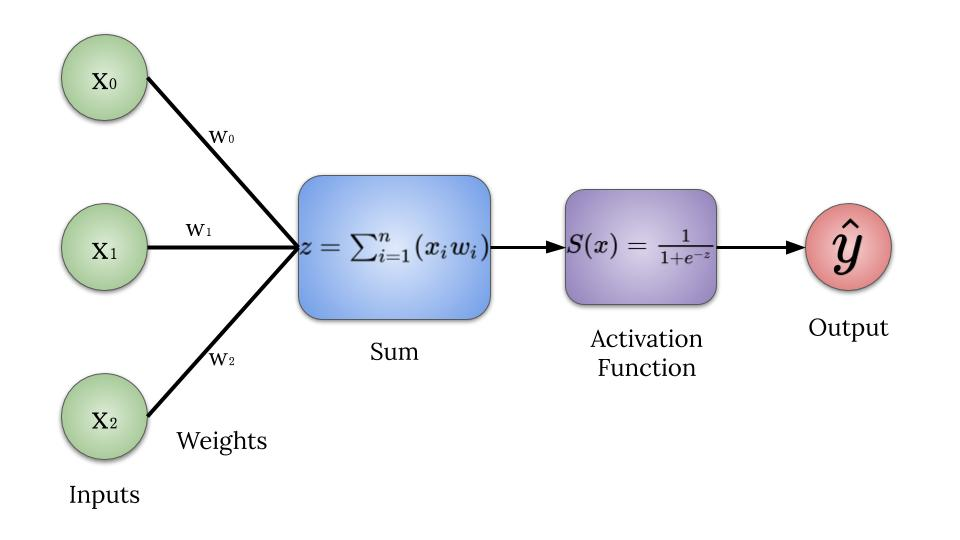

In [15]:
def forward(I1, I2, w1H, w2H, wHO):

    # Hidden layer calculation
    vH = I1 * w1H + I2 * w2H
    fH = sigmoid(vH)

    # Output layer calculation
    vO = fH * wHO
    fO = sigmoid(vO)

    return fH, fO

- `def forward(...)` - Creates the Forward Function
- `I1, I2` Takes two input values
- `w1H, w2H` Takes input-to-hidden weights
- `wHO` Takes hidden-to-output weight
- `vH` Calculates hidden weighted sum
- `fH` Calculates hidden neuron activation
- `vO` Calculates output weighted sum
- `fO` Calculates final output
- `return fH, fO` Returns both neuron outputs

In [16]:
fH, fO = forward(0, 0, w1H, w2H, wHO)

print("Hidden Output:", fH)
print("Final Output:", fO)

Hidden Output: 0.5
Final Output: 0.47502081252106


# Creating the Backward Propagation Function

In the previous step, our Neural Network generated an output.

Now we need to calculate how much error the network made and use that error to calculate two Deltas.
1. Output Delta ($\delta_H$)
2. Hidden Delta ($\delta_o$)    
<br>

**Understand the Error Formula**  

According to your Assignment:
$$
e=d-f_O
$$
Here:
Symbol	Meaning  


*   `d` - 	Actual Target  
*   `fO`-	Predicted Output  
*   `e` -	Prediction Error

<br>

**Calculate Output Delta (δO)**  
In Assignment the formula:
$$
\delta_O=f_O(1-f_O)(d-f_O)
$$

<br>

**Calculate Hidden Delta (δH)**

According to the Assignment:
$$
\delta_H=f_H(1-f_H)\delta_Ow_{HO}
$$

In [17]:
def backward(d, fH, fO, wHO):

    # error calculation
    e = d - fO

    # Calculating output delta
    deltaO = fO * (1 - fO) * e

    # Calculating hidden delta
    deltaH = fH * (1 - fH) * deltaO * wHO

    return e, deltaO, deltaH

In [18]:
# P1 target
d = 0

# Calculate backward values
e, deltaO, deltaH = backward(d, fH, fO, wHO)

print("Error:", e)
print("Output Delta:", deltaO)
print("Hidden Delta:", deltaH)

Error: -0.47502081252106
Output Delta: -0.11845880923571206
Hidden Delta: 0.0059229404617856035


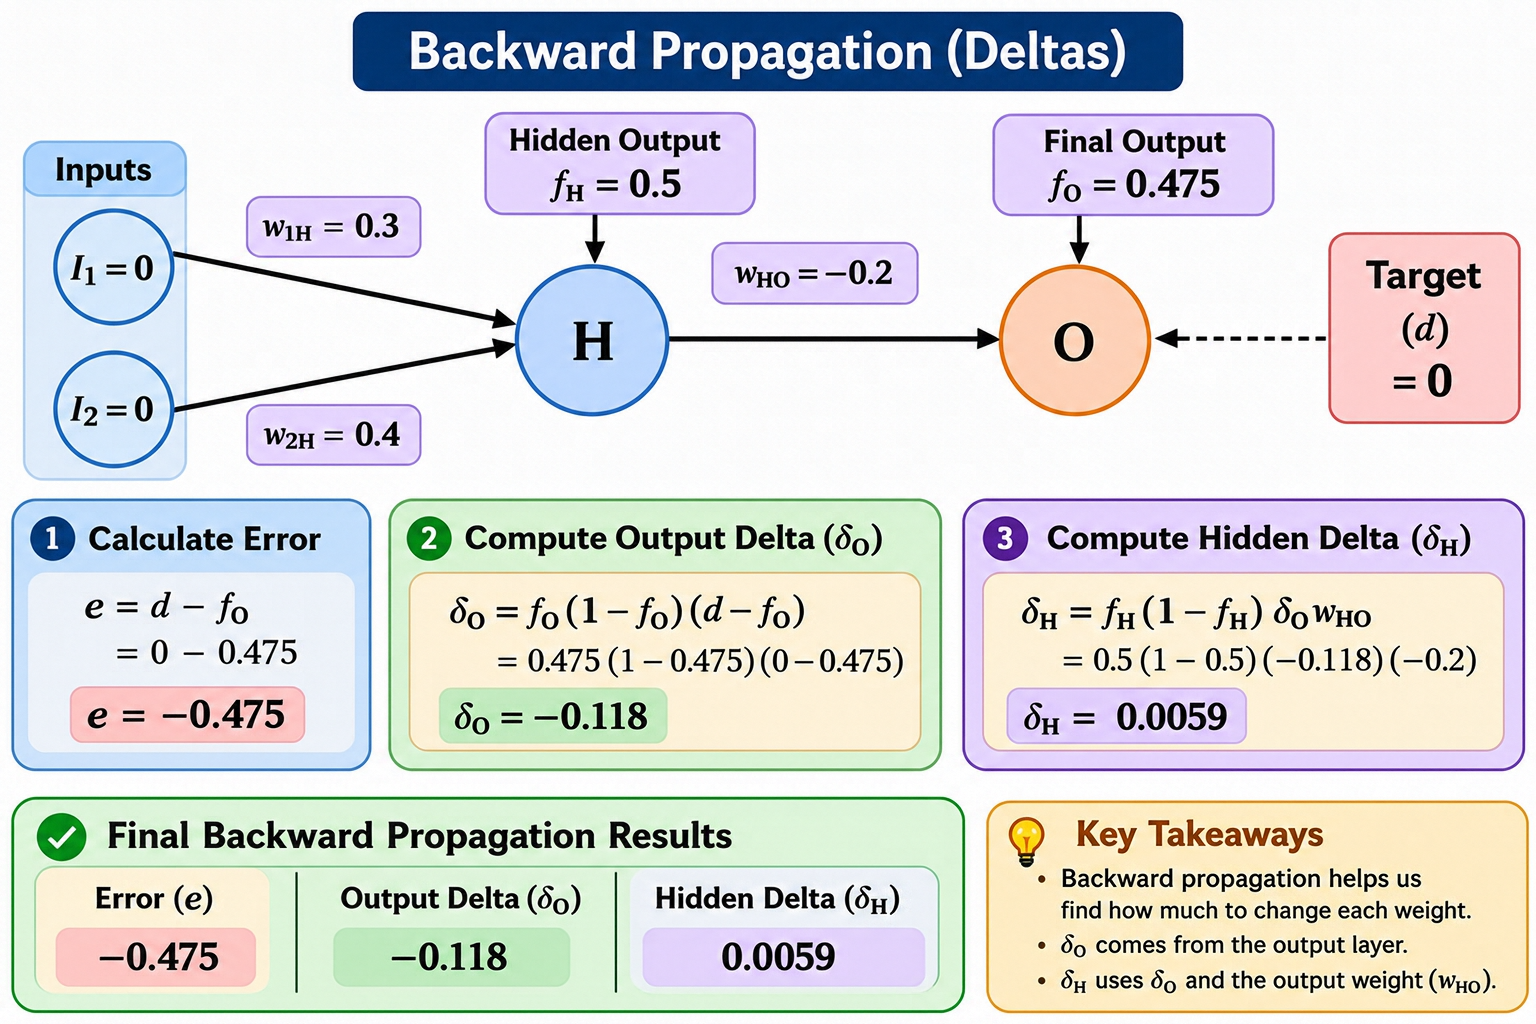

# Calculate Weight Changes

1. Output weight change
$$
\Delta w_{HO}=\mu\Delta w_{HO(prev)}
+\eta(1-\mu)f_H\delta_O
$$

2. First hidden weight change
$$
\Delta w_{1H}=\mu\Delta w_{1H(prev)}
+\eta(1-\mu)I_1\delta_H
$$

3. Second hidden weight change
$$
\Delta w_{2H}=\mu\Delta w_{2H(prev)}
+\eta(1-\mu)I_2\delta_H
$$

In [19]:
# Calculate weight changes

dwHO = mu * dwHO_prev + eta * (1 - mu) * fH * deltaO

dw1H = mu * dw1H_prev + eta * (1 - mu) * 0 * deltaH

dw2H = mu * dw2H_prev + eta * (1 - mu) * 0 * deltaH

print("Change in wHO:", dwHO)
print("Change in w1H:", dw1H)
print("Change in w2H:", dw2H)

Change in wHO: 0.3273346767921965
Change in w1H: 0.05500000000000001
Change in w2H: -0.05500000000000001


# Update the Weights

Formula:
$$
w_{new}=w_{old}+\Delta w
$$

In [20]:
# Update weights

w1H = w1H + dw1H
w2H = w2H + dw2H
wHO = wHO + dwHO

# Update previous weight changes for momentum
dw1H_prev = dw1H
dw2H_prev = dw2H
dwHO_prev = dwHO

print("Updated w1H:", w1H)
print("Updated w2H:", w2H)
print("Updated wHO:", wHO)

Updated w1H: 0.355
Updated w2H: 0.34500000000000003
Updated wHO: 0.1273346767921965


# Start P2 Training
Weights after P1  
w1H = 0.355  
w2H = 0.345  
wHO = 0.1273346767921965



In [21]:
# P2 input
I1 = 1
I2 = 1
d = 1

# Forward propagation
fH, fO = forward(I1, I2, w1H, w2H, wHO)

print("Hidden Output:", fH)
print("Final Output:", fO)

Hidden Output: 0.6681877721681662
Final Output: 0.5212580457823294


In [22]:
# P2 Backward Propagation

e, deltaO, deltaH = backward(d, fH, fO, wHO)

print("Error:", e)
print("Output Delta:", deltaO)
print("Hidden Delta:", deltaH)

Error: 0.47874195421767063
Output Delta: 0.11946914290594896
Hidden Delta: 0.0033728214294772175


In [23]:
# P2 Weight Changes

dwHO = mu * dwHO_prev + eta * (1 - mu) * fH * deltaO

dw1H = mu * dw1H_prev + eta * (1 - mu) * I1 * deltaH

dw2H = mu * dw2H_prev + eta * (1 - mu) * I2 * deltaH

print("Change in wHO:", dwHO)
print("Change in w1H:", dw1H)
print("Change in w2H:", dw2H)

Change in wHO: 0.1836263241555606
Change in w1H: 0.03040177696432648
Change in w2H: -0.03009822303567353


In [24]:
# Update final weights

w1H = w1H + dw1H
w2H = w2H + dw2H
wHO = wHO + dwHO

# Store changes for momentum
dw1H_prev = dw1H
dw2H_prev = dw2H
dwHO_prev = dwHO

print("Final w1H:", w1H)
print("Final w2H:", w2H)
print("Final wHO:", wHO)

Final w1H: 0.3854017769643265
Final w2H: 0.3149017769643265
Final wHO: 0.31096100094775714


# Test the Network

I1 = 0  
I2 = 1  
Target: Unknown

In [25]:
# Test Pattern

I1 = 0
I2 = 1

fH, fO = forward(I1, I2, w1H, w2H, wHO)

print("Test Hidden Output:", fH)
print("Test Final Output:", fO)

Test Hidden Output: 0.5780812761441187
Test Final Output: 0.5448195567141872
